In [38]:
import os
import re
import json
import random
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    accuracy_score, f1_score
)
from sklearn.metrics.pairwise import cosine_similarity

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

PROJECT_DIR = Path("safecampus_artifacts")
PROJECT_DIR.mkdir(exist_ok=True)

print("Python environment ready.")
print("Artifacts will be saved to:", PROJECT_DIR.resolve())

Python environment ready.
Artifacts will be saved to: C:\Users\victus\OneDrive\Desktop\hackathon JP\safecampus_artifacts


In [39]:
templates = {
    "medical": {
        "high": [
            "A student has collapsed near the library and is not responding.",
            "A student is having difficulty breathing outside the lecture hall.",
            "Someone has fainted near the campus medical room.",
            "A student has a serious injury in the sports ground.",
            "A person is unconscious near the main academic block."
        ],
        "medium": [
            "A student feels dizzy near the canteen and needs medical help.",
            "A student has a cut on their hand in the laboratory.",
            "Someone is feeling unwell near the hostel reception.",
            "A student reports a moderate ankle injury near the sports area."
        ],
        "low": [
            "A student requests first-aid supplies for a small paper cut.",
            "Someone needs directions to the campus medical room.",
            "A student asks where to find the first-aid kit."
        ]
    },
    "fire_or_smoke": {
        "high": [
            "Heavy smoke is coming from the electrical room near the lab.",
            "Flames are visible in a campus waste bin near the hostel.",
            "A fire alarm is sounding and smoke is visible in the corridor.",
            "There is a strong burning smell and visible smoke in the workshop."
        ],
        "medium": [
            "A faint burning smell is reported near the computer laboratory.",
            "A student reports a possible smoke smell near the cafeteria."
        ],
        "low": [
            "A student asks where the fire assembly point is.",
            "A fire extinguisher inspection sticker appears out of date."
        ]
    },
    "security": {
        "high": [
            "A person is threatening students near the main gate.",
            "A fight has started outside the hostel and someone may be injured.",
            "A person is attempting to force entry into a restricted laboratory."
        ],
        "medium": [
            "An unknown person is following students near the parking area.",
            "A student reports a suspicious unattended bag near reception."
        ],
        "low": [
            "A student has lost their campus identity card.",
            "A visitor needs help finding the security office."
        ]
    },
    "infrastructure_hazard": {
        "high": [
            "An exposed live electrical wire is lying in a wet corridor.",
            "A ceiling panel has fallen and people may be in danger.",
            "A large water leak is near electrical equipment in the lab."
        ],
        "medium": [
            "Water is leaking in the hostel corridor.",
            "A broken stair handrail has been reported in the academic block."
        ],
        "low": [
            "A classroom light is not working.",
            "A door handle is broken in the library."
        ]
    },
    "other": {
        "high": [
            "A campus emergency exit is blocked during an evacuation."
        ],
        "medium": [
            "Several students are stuck in a lift and have called for assistance."
        ],
        "low": [
            "A student has found a lost notebook near the library.",
            "Someone wants information about the campus lost-and-found office."
        ]
    }
}

locations = [
    "library", "main gate", "hostel", "computer laboratory",
    "canteen", "sports ground", "academic block", "workshop",
    "parking area", "medical room", "lecture hall"
]
prefixes = [
    "Reported near the {location}: ",
    "Location: {location}. ",
    "At the {location}, ",
    "Campus report from {location}: ",
    ""
]

records = []
counter = 1
for category, urgency_dict in templates.items():
    for urgency, examples in urgency_dict.items():
        for base in examples:
            for variant in range(8):
                loc = random.choice(locations)
                prefix = random.choice(prefixes).format(location=loc)
                text = prefix + base
                # A few harmless variations simulate noisy user reports.
                if variant % 4 == 1:
                    text = text.lower()
                elif variant % 4 == 2:
                    text = text.replace("student", "person")
                elif variant % 4 == 3:
                    text = text + " Please send assistance."
                language = "en"
                records.append({
                    "incident_id": f"SYN-{counter:05d}",
                    "description": text,
                    "category": category,
                    "urgency_label": urgency,
                    "location_text": loc,
                    "language": language,
                    "duplicate_group_id": f"G-{counter:05d}"
                })
                counter += 1

raw_df = pd.DataFrame(records)

# Add a few intentionally imperfect records to demonstrate cleaning.
raw_df.loc[0, "description"] = "  " + raw_df.loc[0, "description"] + "  "
raw_df.loc[1, "location_text"] = None
raw_df.loc[2, "description"] = None
raw_df.loc[3, "category"] = None

# Save raw data for transparency.
raw_df.to_csv(PROJECT_DIR / "synthetic_incidents_raw.csv", index=False)

print("Raw dataset shape:", raw_df.shape)
display(raw_df.head(10))

Raw dataset shape: (304, 7)


,incident_id,description,category,urgency_label,location_text,language,duplicate_group_id
0,SYN-00001,Reported near the lecture hall: A student ha...,medical,high,lecture hall,en,G-00001
1,SYN-00002,"at the library, a student has collapsed near t...",medical,high,NaN,en,G-00002
2,SYN-00003,NaN,medical,high,computer laboratory,en,G-00003
3,SYN-00004,Reported near the hostel: A student has collap...,NaN,high,hostel,en,G-00004
4,SYN-00005,A student has collapsed near the library and i...,medical,high,lecture hall,en,G-00005
5,SYN-00006,a student has collapsed near the library and i...,medical,high,main gate,en,G-00006
6,SYN-00007,Reported near the academic block: A person has...,medical,high,academic block,en,G-00007
7,SYN-00008,Reported near the library: A student has colla...,medical,high,library,en,G-00008
8,SYN-00009,Location: computer laboratory. A student is ha...,medical,high,computer laboratory,en,G-00009
9,SYN-00010,a student is having difficulty breathing outsi...,medical,high,parking area,en,G-00010


In [40]:
df = raw_df.copy()

def clean_text(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    value = re.sub(r"\\s+", " ", value)
    return value if value else np.nan

for col in ["description", "category", "urgency_label", "location_text", "language"]:
    df[col] = df[col].apply(clean_text)

for col in ["category", "urgency_label", "language"]:
    df[col] = df[col].str.lower()

df["location_text"] = df["location_text"].fillna("unknown").str.lower()

valid_categories = set(templates.keys())
valid_urgencies = {"low", "medium", "high"}

before = len(df)
df = df.dropna(subset=["description", "category", "urgency_label"])
df = df[df["category"].isin(valid_categories)]
df = df[df["urgency_label"].isin(valid_urgencies)]
df = df.drop_duplicates(subset=["description", "category", "urgency_label"])
df = df.reset_index(drop=True)

print(f"Rows before cleaning: {before}")
print(f"Rows after cleaning:  {len(df)}")
print("\nMissing values after cleaning:")
display(df.isna().sum().to_frame("missing_count"))
print("\nCategory distribution:")
display(df["category"].value_counts().to_frame("rows"))
print("\nUrgency distribution:")
display(df["urgency_label"].value_counts().to_frame("rows"))

df.to_csv(PROJECT_DIR / "synthetic_incidents_clean.csv", index=False)
display(df.head())

Rows before cleaning: 304
Rows after cleaning:  288

Missing values after cleaning:


,missing_count
incident_id,0
description,0
category,0
urgency_label,0
location_text,0
language,0
duplicate_group_id,0



Category distribution:


,rows
category,
medical,92
fire_or_smoke,59
security,55
infrastructure_hazard,53
other,29



Urgency distribution:


,rows
urgency_label,
high,121
medium,84
low,83


,incident_id,description,category,urgency_label,location_text,language,duplicate_group_id
0,SYN-00001,Reported near the lecture hall: A student has ...,medical,high,lecture hall,en,G-00001
1,SYN-00002,"at the library, a student has collapsed near t...",medical,high,unknown,en,G-00002
2,SYN-00005,A student has collapsed near the library and i...,medical,high,lecture hall,en,G-00005
3,SYN-00006,a student has collapsed near the library and i...,medical,high,main gate,en,G-00006
4,SYN-00007,Reported near the academic block: A person has...,medical,high,academic block,en,G-00007


## 3. Explore the cleaned data

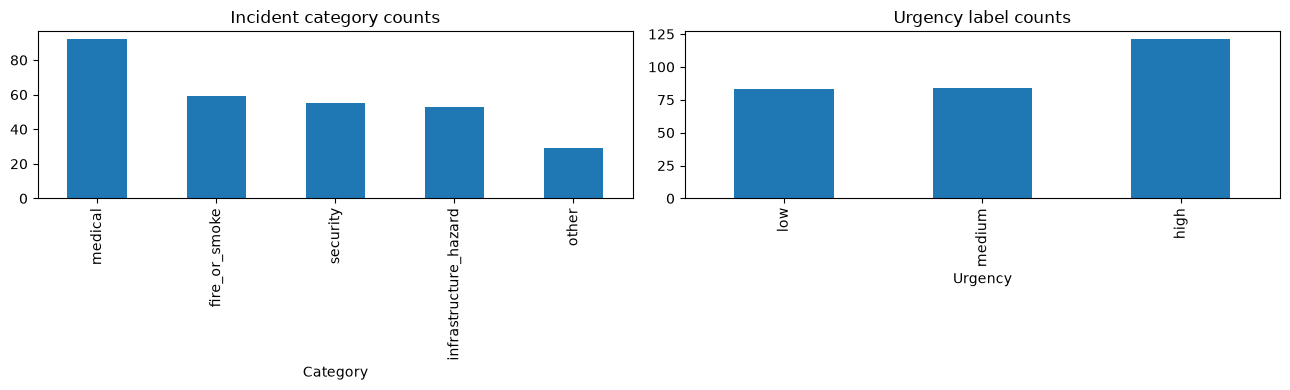

Description length summary:


,characters
count,288.000000
mean,83.385417
std,18.749980
min,33.000000
25%,71.000000
50%,83.000000
75%,95.000000
max,126.000000


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["category"].value_counts().plot(kind="bar", ax=axes[0], title="Incident category counts")
df["urgency_label"].value_counts().reindex(["low", "medium", "high"]).plot(
    kind="bar", ax=axes[1], title="Urgency label counts"
)
axes[0].set_xlabel("Category")
axes[1].set_xlabel("Urgency")
plt.tight_layout()
plt.show()

print("Description length summary:")
display(df["description"].str.len().describe().to_frame("characters"))

Accuracy: 1.0
Macro F1: 1.0
                       precision    recall  f1-score   support

        fire_or_smoke       1.00      1.00      1.00        12
infrastructure_hazard       1.00      1.00      1.00        11
              medical       1.00      1.00      1.00        18
                other       1.00      1.00      1.00         6
             security       1.00      1.00      1.00        11

             accuracy                           1.00        58
            macro avg       1.00      1.00      1.00        58
         weighted avg       1.00      1.00      1.00        58



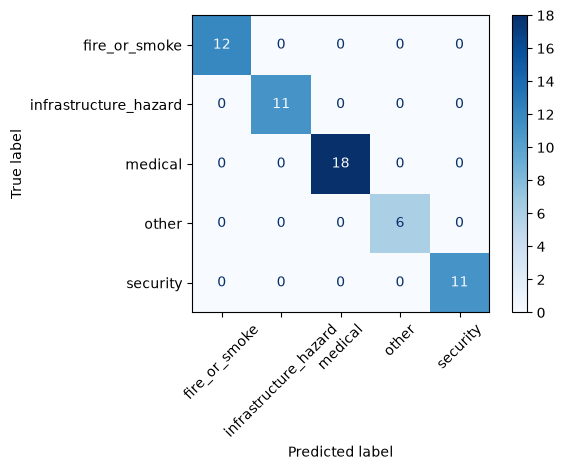

Saved: safecampus_artifacts\incident_category_model.joblib


In [42]:
X = df["description"].astype(str)
y = df["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

category_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced"))
])
category_model.fit(X_train, y_train)

category_predictions = category_model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, category_predictions), 4))
print("Macro F1:", round(f1_score(y_test, category_predictions, average="macro"), 4))
print(classification_report(y_test, category_predictions, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, category_predictions, xticks_rotation=45, cmap="Blues"
)
plt.tight_layout()
plt.show()

joblib.dump(category_model, PROJECT_DIR / "incident_category_model.joblib")
print("Saved:", PROJECT_DIR / "incident_category_model.joblib")

In [43]:
X_u = df["description"].astype(str)
y_u = df["urgency_label"]

Xu_train, Xu_test, yu_train, yu_test = train_test_split(
    X_u, y_u, test_size=0.20, random_state=RANDOM_STATE, stratify=y_u
)

urgency_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced"))
])
urgency_model.fit(Xu_train, yu_train)

urgency_predictions = urgency_model.predict(Xu_test)
print("Urgency accuracy:", round(accuracy_score(yu_test, urgency_predictions), 4))
print("Urgency macro F1:", round(f1_score(yu_test, urgency_predictions, average="macro"), 4))
print(classification_report(yu_test, urgency_predictions, zero_division=0))

joblib.dump(urgency_model, PROJECT_DIR / "urgency_model.joblib")
print("Saved:", PROJECT_DIR / "urgency_model.joblib")

Urgency accuracy: 1.0
Urgency macro F1: 1.0
              precision    recall  f1-score   support

        high       1.00      1.00      1.00        24
         low       1.00      1.00      1.00        17
      medium       1.00      1.00      1.00        17

    accuracy                           1.00        58
   macro avg       1.00      1.00      1.00        58
weighted avg       1.00      1.00      1.00        58

Saved: safecampus_artifacts\urgency_model.joblib


In [44]:
URGENT_PATTERNS = [
    r"unconscious", r"not responding", r"difficulty breathing",
    r"heavy smoke", r"flames", r"live electrical wire",
    r"threatening students", r"force entry"
]

def urgent_rule_check(description):
    text = str(description).lower()
    matched = [p for p in URGENT_PATTERNS if re.search(p, text)]
    return {
        "urgent_rule_triggered": bool(matched),
        "matched_rules": matched,
        "action": "trigger approved urgent workflow immediately"
                  if matched else "continue normal assessment and human review"
    }

for sample in [
    "A student is unconscious near the library",
    "A classroom light is not working"
]:
    print(sample)
    print(urgent_rule_check(sample))
    print()

A student is unconscious near the library
{'urgent_rule_triggered': True, 'matched_rules': ['unconscious'], 'action': 'trigger approved urgent workflow immediately'}

A classroom light is not working
{'urgent_rule_triggered': False, 'matched_rules': [], 'action': 'continue normal assessment and human review'}



In [45]:
def assess_report(description):
    category_probabilities = category_model.predict_proba([description])[0]
    category_classes = category_model.named_steps["classifier"].classes_
    best_category_idx = int(np.argmax(category_probabilities))

    urgency_probabilities = urgency_model.predict_proba([description])[0]
    urgency_classes = urgency_model.named_steps["classifier"].classes_
    best_urgency_idx = int(np.argmax(urgency_probabilities))

    return {
        "description": description,
        "predicted_category": str(category_classes[best_category_idx]),
        "category_model_score": float(category_probabilities[best_category_idx]),
        "predicted_urgency": str(urgency_classes[best_urgency_idx]),
        "urgency_model_score": float(urgency_probabilities[best_urgency_idx]),
        **urgent_rule_check(description)
    }

test_reports = [
    "A student has collapsed and is not responding near the library",
    "Smoke is coming from the computer laboratory",
    "A classroom light is not working"
]
display(pd.DataFrame([assess_report(x) for x in test_reports]))

,description,predicted_category,category_model_score,predicted_urgency,urgency_model_score,urgent_rule_triggered,matched_rules,action
0,A student has collapsed and is not responding ...,medical,0.525122,high,0.590268,True,[not responding],trigger approved urgent workflow immediately
1,Smoke is coming from the computer laboratory,fire_or_smoke,0.693228,high,0.603769,False,[],continue normal assessment and human review
2,A classroom light is not working,infrastructure_hazard,0.716591,low,0.841084,False,[],continue normal assessment and human review


In [46]:
def find_similar_reports(new_description, descriptions=None, threshold=0.45, top_k=5):
    if descriptions is None:
        descriptions = df["description"].tolist()
    descriptions = [str(x) for x in descriptions]
    vectorizer = TfidfVectorizer(ngram_range=(1, 2))
    matrix = vectorizer.fit_transform(descriptions + [str(new_description)])
    scores = cosine_similarity(matrix[-1], matrix[:-1]).ravel()
    indices = np.argsort(scores)[::-1][:top_k]
    results = []
    for idx in indices:
        if scores[idx] >= threshold:
            results.append({
                "description": descriptions[idx],
                "similarity": float(scores[idx])
            })
    return pd.DataFrame(results)

find_similar_reports(
    "A student collapsed near the library and is not responding",
    threshold=0.25
)

,description,similarity
0,a student has collapsed near the library and i...,0.841658
1,A student has collapsed near the library and i...,0.841658
2,"at the library, a student has collapsed near t...",0.785282
3,Reported near the lecture hall: A student has ...,0.727295
4,Reported near the library: A student has colla...,0.724988


In [47]:
responders = pd.DataFrame([
    {"responder_id": "R-101", "role": "medical", "distance_m": 150, "available": True, "active_jobs": 0},
    {"responder_id": "R-102", "role": "security", "distance_m": 50, "available": True, "active_jobs": 0},
    {"responder_id": "R-103", "role": "medical", "distance_m": 300, "available": True, "active_jobs": 1},
    {"responder_id": "R-104", "role": "medical", "distance_m": 100, "available": False, "active_jobs": 0},
])

ROLE_MAP = {
    "medical": {"medical"},
    "fire_or_smoke": {"fire", "security"},
    "security": {"security"},
    "infrastructure_hazard": {"maintenance", "security"},
    "other": {"security", "campus_support"}
}

def recommend_responders(incident_category, responder_df=responders, top_k=5):
    eligible_roles = ROLE_MAP.get(incident_category, set())
    candidates = responder_df.copy()
    candidates = candidates[candidates["available"] == True].copy()
    candidates = candidates[candidates["role"].isin(eligible_roles)].copy()
    if candidates.empty:
        return candidates.assign(score=pd.Series(dtype=float))

    # Transparent demonstration score; tune only with operational stakeholders.
    candidates["skill_score"] = 1.0
    candidates["distance_score"] = 1 / (1 + candidates["distance_m"] / 100)
    candidates["load_score"] = 1 / (1 + candidates["active_jobs"])
    candidates["score"] = (
        0.50 * candidates["skill_score"]
        + 0.30 * candidates["distance_score"]
        + 0.20 * candidates["load_score"]
    )
    return candidates.sort_values("score", ascending=False).head(top_k)

recommend_responders("medical")

,responder_id,role,distance_m,available,active_jobs,skill_score,distance_score,load_score,score
0,R-101,medical,150,True,0,1.0,0.40,1.0,0.820
2,R-103,medical,300,True,1,1.0,0.25,0.5,0.675


In [ ]:
def llm_extract_incident(description):
    """Optional OpenAI API example. Returns None when package/key is unavailable."""
    api_key = os.getenv("OPENAI_API_KEY")
    if not api_key:
        print("OPENAI_API_KEY not set; skipping LLM call.")
        return None
    try:
        from openai import OpenAI
        client = OpenAI(api_key=api_key)
        response = client.chat.completions.create(
            model=os.getenv("SAFECAMPUS_LLM_MODEL", "gpt-4.1-mini"),
            messages=[
                {
                    "role": "system",
                    "content": (
                        "Extract incident details as JSON with keys: "
                        "summary, reported_location, people_at_risk, missing_information. "
                        "Do not diagnose or decide whether to dispatch emergency services. "
                        "Use null or an empty list for unknown details."
                    )
                },
                {"role": "user", "content": str(description)}
            ],
            response_format={"type": "json_object"},
            temperature=0
        )
        return json.loads(response.choices[0].message.content)
    except Exception as exc:
        print("LLM call failed:", type(exc).__name__, str(exc)[:250])
        return None


In [ ]:
def transcribe_audio(audio_path, model_size="base"):
    try:
        import whisper
    except ImportError:
        print("Whisper is not installed. Uncomment the install cell first.")
        return None
    if not Path(audio_path).exists():
        print("Audio file not found:", audio_path)
        return None
    model = whisper.load_model(model_size)
    result = model.transcribe(str(audio_path))
    return result.get("text", "").strip()


In [ ]:
def describe_image(image_path):
    try:
        from transformers import pipeline
    except ImportError:
        print("Install transformers, torch and pillow to enable image captioning.")
        return None
    if not Path(image_path).exists():
        print("Image file not found:", image_path)
        return None
    try:
        captioner = pipeline(
            "image-to-text",
            model="Salesforce/blip-image-captioning-base"
        )
        return captioner(str(image_path))
    except Exception as exc:
        print("Image captioning failed:", type(exc).__name__, str(exc)[:250])
        return None


In [ ]:
df.to_csv(PROJECT_DIR / "incidents_clean.csv", index=False)
joblib.dump(category_model, PROJECT_DIR / "incident_category_model.joblib")
joblib.dump(urgency_model, PROJECT_DIR / "urgency_model.joblib")

def predict_incident(description):
    return assess_report(description)

example = predict_incident(
    "Fictional report: smoke is coming from the workshop"
)
print(json.dumps(example, indent=2))
print("\nSaved files:")
for path in sorted(PROJECT_DIR.iterdir()):
    print("-", path.name)

{
  "description": "Fictional report: smoke is coming from the workshop",
  "predicted_category": "fire_or_smoke",
  "category_model_score": 0.6465934168054924,
  "predicted_urgency": "high",
  "urgency_model_score": 0.6677162875532516,
  "urgent_rule_triggered": false,
  "matched_rules": [],
  "action": "continue normal assessment and human review"
}

Saved files:
- incident_category_model.joblib
- incidents_clean.csv
- synthetic_incidents_clean.csv
- synthetic_incidents_raw.csv
- urgency_model.joblib


In [55]:
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (288, 7)
Columns: ['incident_id', 'description', 'category', 'urgency_label', 'location_text', 'language', 'duplicate_group_id']


,incident_id,description,category,urgency_label,location_text,language,duplicate_group_id
0,SYN-00001,Reported near the lecture hall: A student has ...,medical,high,lecture hall,en,G-00001
1,SYN-00002,"at the library, a student has collapsed near t...",medical,high,unknown,en,G-00002
2,SYN-00005,A student has collapsed near the library and i...,medical,high,lecture hall,en,G-00005
3,SYN-00006,a student has collapsed near the library and i...,medical,high,main gate,en,G-00006
4,SYN-00007,Reported near the academic block: A person has...,medical,high,academic block,en,G-00007
